# Decision Tree for a Stock Order (ABA Unit 2, Practical 5)

**Aim:** develop a decision model for a business decision under uncertainty: payoff-table criteria, EMV, EVPI and decision-tree rollback, with probabilities estimated from the sales data.

Run the cells in order (Runtime → Run all). Nothing to install. The note `decision-analysis-practical` on Sutra explains every step.

In [1]:
# Step 1. Load the data: how much do festival days lift Supermarket sales above a normal day?
import numpy as np
import pandas as pd

url = ("https://raw.githubusercontent.com/Prathameshv07/ai-ds-notes/main/"
       "content/assets/data/sahyadri-mart-sales.csv")
df = pd.read_csv(url, parse_dates=["date"])
normal_day = df[df["is_festival"] == 0].groupby("store_id")["revenue_inr"].median()
fest = df[(df["is_festival"] == 1) & (df["store_type"] == "Supermarket")].copy()
fest["uplift"] = fest["revenue_inr"] / fest["store_id"].map(normal_day)
print(f"Supermarket festival days: {len(fest)}")
print(fest["uplift"].describe().round(2).to_string())

Supermarket festival days: 160
count    160.00
mean       1.60
std        0.43
min        0.88
25%        1.28
50%        1.51
75%        1.88
max        3.13


In [2]:
# Step 2. States of nature: Low (uplift below 1.3), Medium (1.3 to 1.7), High (1.7 or more)
fest["demand"] = pd.cut(fest["uplift"], bins=[0, 1.3, 1.7, np.inf], right=False, labels=["Low", "Medium", "High"])
prob = fest["demand"].value_counts(normalize=True).reindex(["High", "Medium", "Low"])
print(prob.round(3).to_string())

demand
High      0.331
Medium    0.400
Low       0.269


In [3]:
# Step 3. Payoff table (profit, Rs thousand) and the four criteria without probabilities
pay = pd.DataFrame({"High": [200, 120, 60], "Medium": [80, 100, 60], "Low": [-60, 20, 40]},
                   index=["Large order", "Medium order", "Small order"])
regret = pay.max() - pay                         # best payoff in each state minus each payoff
crit = pd.DataFrame({"maximax": pay.max(axis=1), "maximin": pay.min(axis=1),
                     "Laplace": pay.mean(axis=1).round(1), "max regret": regret.max(axis=1)})
print(crit.to_string())
print("\nMaximax ->", crit["maximax"].idxmax(), "| Maximin ->", crit["maximin"].idxmax(),
      "| Laplace ->", crit["Laplace"].idxmax(), "| Minimax regret ->", crit["max regret"].idxmin())

              maximax  maximin  Laplace  max regret
Large order       200      -60     73.3         100
Medium order      120       20     80.0          80
Small order        60       40     53.3         140

Maximax -> Large order | Maximin -> Small order | Laplace -> Medium order | Minimax regret -> Medium order


In [4]:
# Step 4. With probabilities from the data: EMV, EOL and EVPI
emv = (pay * prob).sum(axis=1)
eol = (regret * prob).sum(axis=1)
ev_perfect = (pay.max() * prob).sum()
print(pd.DataFrame({"EMV": emv.round(2), "EOL": eol.round(2)}).to_string())
print(f"\nBest by EMV: {emv.idxmax()} (EMV {emv.max():.2f})")
print(f"EV with perfect information {ev_perfect:.2f} -> EVPI = {ev_perfect - emv.max():.2f} (= min EOL {eol.min():.2f})")

                EMV    EOL
Large order   82.12  34.88
Medium order  85.12  31.88
Small order   54.62  62.38

Best by EMV: Medium order (EMV 85.12)
EV with perfect information 117.00 -> EVPI = 31.88 (= min EOL 31.88)


In [5]:
# Step 5. The same decision as a tree, solved by rolling back
def rollback(node):
    """Return the expected value of a node and print the choice at each decision node."""
    if node["type"] == "end":
        return node["payoff"]
    if node["type"] == "chance":
        return sum(p * rollback(child) for p, child in node["branches"])
    values = {name: rollback(child) for name, child in node["options"].items()}
    best = max(values, key=values.get)
    print("Decision:", {k: round(float(v), 2) for k, v in values.items()}, "->", best)
    return values[best]

def chance(h, m, l):
    return {"type": "chance", "branches": [(prob["High"], {"type": "end", "payoff": h}),
                                           (prob["Medium"], {"type": "end", "payoff": m}),
                                           (prob["Low"], {"type": "end", "payoff": l})]}

tree = {"type": "decision", "options": {"Large": chance(200, 80, -60),
                                        "Medium": chance(120, 100, 20),
                                        "Small": chance(60, 60, 40)}}
print(f"Value of the tree: {rollback(tree):.2f}")

Decision: {'Large': 82.12, 'Medium': 85.12, 'Small': 54.62} -> Medium
Value of the tree: 85.12


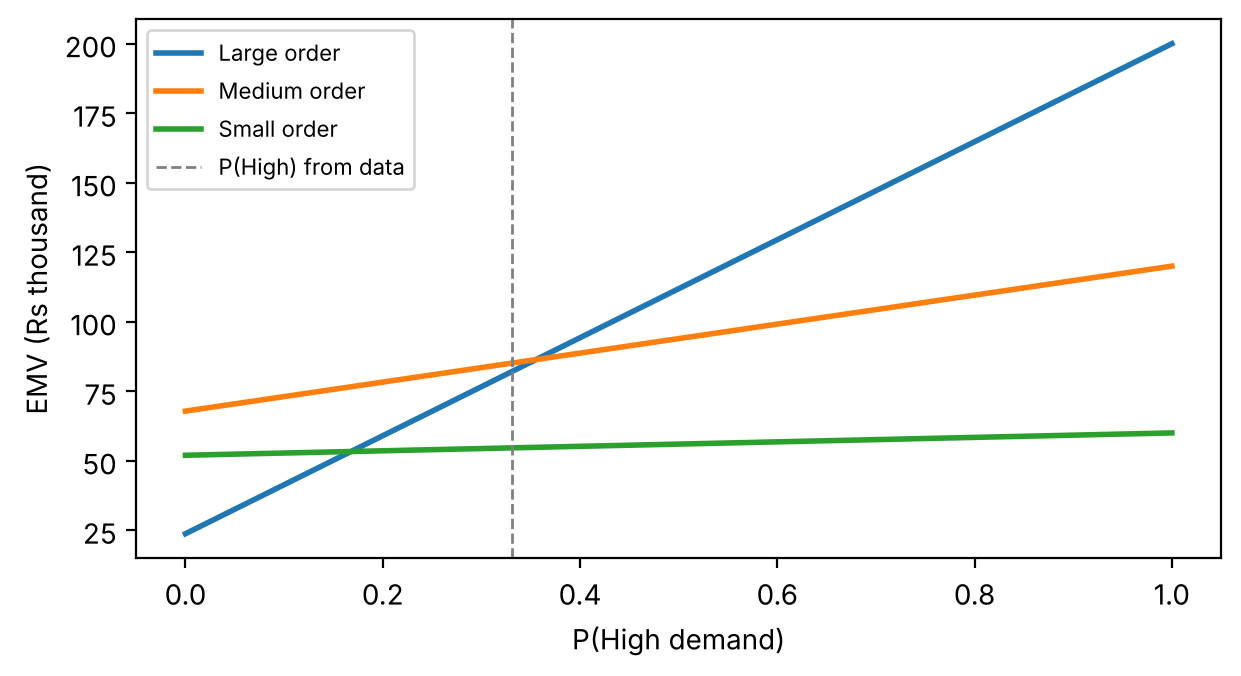

Large overtakes Medium when P(High) exceeds about 0.36


In [6]:
# Step 6. Sensitivity: how does the best order change with P(High)?
import matplotlib.pyplot as plt

ph = np.linspace(0, 1, 101)
ratio = prob["Medium"] / (prob["Medium"] + prob["Low"])     # keep Medium:Low in the data's proportion
pm, pl = (1 - ph) * ratio, (1 - ph) * (1 - ratio)
curves = {name: row["High"] * ph + row["Medium"] * pm + row["Low"] * pl for name, row in pay.iterrows()}
fig, ax = plt.subplots(figsize=(7, 3.5))
for name, y in curves.items():
    ax.plot(ph, y, lw=2, label=name)
ax.axvline(prob["High"], color="grey", ls="--", lw=1, label="P(High) from data")
ax.set_xlabel("P(High demand)")
ax.set_ylabel("EMV (Rs thousand)")
ax.legend(fontsize=8)
plt.show()
cross = ph[np.argmax(curves["Large order"] > curves["Medium order"])]
print(f"Large overtakes Medium when P(High) exceeds about {cross:.2f}")